# 13 · Validación del modelo

**Fase CRISP-DM:** 5. Evaluación

**Objetivo:** antes de tocar la prueba, responder con evidencia cuatro preguntas:

1. **¿Sobreajusta?** Curvas de aprendizaje y brecha entre entrenamiento y validación.
2. **¿La mejora es real o es ruido?** Pruebas pareadas **por comensal** (permutación y bootstrap) con intervalos de confianza.
3. **¿Hay datos suficientes para verla?** Análisis de potencia Monte Carlo.
4. **¿Qué pasa con alguien nuevo?** Arranque en frío **contrafactual** (notebook 10): las mismas consultas, como si la persona o el restaurante no tuvieran historia.

**Criterio fijado antes de ver la prueba** (`config/models.yaml`): una mejora vale la pena si es de al menos **0.01 de NDCG@3**. En una lista de 3 a 5 platillos, menos que eso no se nota y no paga mantener un modelo más complejo.

Todo se mide en **validación (mes 10)**. La prueba se usa una sola vez en el notebook 15.

> Este notebook solo narra el algoritmo. La lógica vive en `src/puzzle_recsys`.

## Configuración

In [1]:
import json

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from puzzle_recsys.config import load_paths, load_simulation, load_yaml
from puzzle_recsys.evaluation.metrics import rank_metrics, summarize
from puzzle_recsys.evaluation.power import power_curve
from puzzle_recsys.evaluation.resampling import bootstrap_ci
from puzzle_recsys.evaluation.statistical_tests import paired_bootstrap, paired_permutation
from puzzle_recsys.features.build import as_new_restaurant, without_history
from puzzle_recsys.profiles.diner_profile import cuisine_prior
from puzzle_recsys.ranking.baselines import popularity_score
from puzzle_recsys.ranking.feature_sets import FOR_YOU, model_frame
from puzzle_recsys.ranking.lgbm_ranker import predict, to_lgbm
from puzzle_recsys.repository.parquet_repo import ParquetRepository, run_id_for
from puzzle_recsys.runtime import keep_awake
from puzzle_recsys.simulation.distributions import make_rng

keep_awake()
paths, sim, mcfg = load_paths(), load_simulation(), load_yaml("models")
SEED, ecfg = sim.seed, mcfg["evaluation"]
MIN_GAIN = ecfg["min_relevant_improvement"]
ti = pd.read_parquet(paths.data_model / "para_ti.parquet")
ti = ti[ti["split"].isin(["train", "valid"])]
train, valid = ti[ti["split"] == "train"], ti[ti["split"] == "valid"]
meta = json.loads((paths.models / "lgbm_meta.json").read_text(encoding="utf-8"))["para_ti"]
lgbm = lgb.Booster(model_file=str(paths.models / "lgbm_para_ti.txt"))
logistica = joblib.load(paths.models / "logistica_para_ti.joblib")
cats, best, n_trees = meta["categories"], meta["params"], meta["best_iteration"]
cols = list(FOR_YOU.columns)

def puntuar(df):
    return {"popularidad": popularity_score(df, min_orders=0).to_numpy(),
            "logística": logistica.predict_proba(model_frame(df, FOR_YOU)[cols])[:, 1],
            "lgbm": predict(lgbm, df, FOR_YOU, cats)}

def por_consulta(df, scores):
    q = df.drop_duplicates("query_id").set_index("query_id")[["diner_id", "course", "tramo_historia", "onboarding_completo"]]
    return {k: rank_metrics(df.assign(score=s), ks=(3,), seed=SEED).join(q, on="query_id") for k, s in scores.items()}

pq = por_consulta(valid, puntuar(valid))
pd.DataFrame({k: summarize(v)[["consultas", "ndcg@3", "hit@3"]].iloc[0] for k, v in pq.items()}).T.round(4)

,consultas,ndcg@3,hit@3
popularidad,40056.0,0.6565,0.7938
logística,40056.0,0.7027,0.8396
lgbm,40056.0,0.7371,0.8659


## 1. Curvas de aprendizaje

Se entrena LightGBM, con los hiperparámetros elegidos y el número de árboles fijo, usando el 5 %, 10 %, 25 %, 50 % y 100 % de las consultas de entrenamiento. Para cada tamaño se mide el NDCG@3 **en las consultas con que se entrenó** (hasta 20,000) y **en validación**.

- Si la validación **sigue subiendo** al final, más datos ayudarían.
- Si entrenamiento y validación quedan **lejos**, el modelo memoriza (sobreajuste).

,% del entrenamiento,consultas,NDCG@3 train,NDCG@3 valid,brecha
0,5,18073,0.9010,0.7212,0.1798
1,10,36147,0.8450,0.7281,0.1170
2,25,90367,0.7949,0.7335,0.0614
3,50,180735,0.7704,0.7350,0.0354
4,100,361470,0.7541,0.7371,0.0170


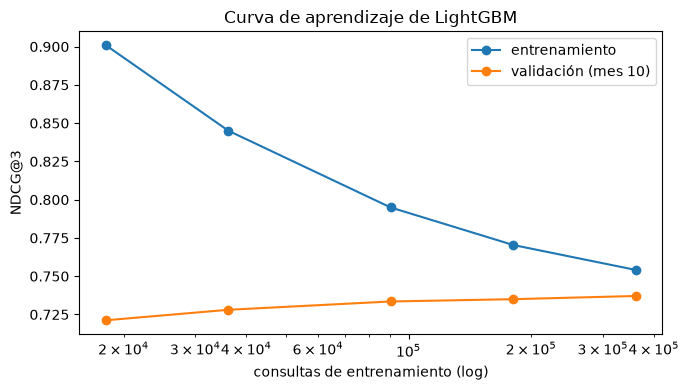

In [2]:
qids = train["query_id"].unique()
rng = make_rng(SEED, "learning_curve")
orden_q = rng.permutation(qids)
curva = []
for frac in [0.05, 0.10, 0.25, 0.50, 1.00]:
    sub_q = set(orden_q[: int(frac * len(orden_q))])
    sub = train[train["query_id"].isin(sub_q)]
    d = to_lgbm(sub, FOR_YOU, cats)
    b = lgb.train({"objective": "lambdarank", "metric": "ndcg", "eval_at": [3], "seed": SEED, "deterministic": True,
                   "force_row_wise": True, "verbose": -1, **best}, lgb.Dataset(d.X, d.y, group=d.group),
                  num_boost_round=n_trees)
    muestra_q = set(list(sub_q)[:20_000])
    tr_eval = sub[sub["query_id"].isin(muestra_q)]
    nd_tr = summarize(rank_metrics(tr_eval.assign(score=predict(b, tr_eval, FOR_YOU, cats)), ks=(3,), seed=SEED))["ndcg@3"].iloc[0]
    nd_va = summarize(rank_metrics(valid.assign(score=predict(b, valid, FOR_YOU, cats)), ks=(3,), seed=SEED))["ndcg@3"].iloc[0]
    curva.append({"% del entrenamiento": int(100 * frac), "consultas": len(sub_q), "NDCG@3 train": nd_tr, "NDCG@3 valid": nd_va})
curva = pd.DataFrame(curva)
curva["brecha"] = curva["NDCG@3 train"] - curva["NDCG@3 valid"]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curva["consultas"], curva["NDCG@3 train"], marker="o", label="entrenamiento")
ax.plot(curva["consultas"], curva["NDCG@3 valid"], marker="o", label="validación (mes 10)")
ax.set_xscale("log"); ax.set_xlabel("consultas de entrenamiento (log)"); ax.set_ylabel("NDCG@3")
ax.set_title("Curva de aprendizaje de LightGBM"); ax.legend()
fig.tight_layout(); fig.savefig(paths.figures / "13_curva_aprendizaje.png", dpi=150)
curva.round(4)

## 2. Brecha entre entrenamiento y validación

La misma comparación para la regresión logística, en una muestra de 20,000 consultas de entrenamiento. Un modelo lineal casi no puede memorizar, así que su brecha sirve de referencia.

In [3]:
muestra_tr = train[train["query_id"].isin(set(orden_q[:20_000]))]
brecha = []
for nombre, s_tr, s_va in [
    ("logística", logistica.predict_proba(model_frame(muestra_tr, FOR_YOU)[cols])[:, 1], None),
    ("lgbm", predict(lgbm, muestra_tr, FOR_YOU, cats), None),
]:
    nd_tr = summarize(rank_metrics(muestra_tr.assign(score=s_tr), ks=(3,), seed=SEED))["ndcg@3"].iloc[0]
    nd_va = summarize(pq[nombre])["ndcg@3"].iloc[0]
    brecha.append({"modelo": nombre, "NDCG@3 train": nd_tr, "NDCG@3 valid": nd_va, "brecha": nd_tr - nd_va})
pd.DataFrame(brecha).round(4)

,modelo,NDCG@3 train,NDCG@3 valid,brecha
0,logística,0.7083,0.7027,0.0056
1,lgbm,0.7579,0.7371,0.0208


## 3. Pruebas pareadas por comensal

Se compara **consulta por consulta** (los modelos se evalúan sobre las mismas consultas) y la aleatorización se hace **por persona**: las consultas de alguien no son independientes entre sí.

- **Intervalo de confianza** del NDCG@3 de cada modelo (bootstrap por persona, 2,000 remuestreos).
- **Permutación** (5,000 cambios de signo por persona): p-valor de la diferencia.
- **Bootstrap pareado**: intervalo de confianza de la diferencia. Si no incluye 0, la diferencia es real; si además supera 0.01, es **relevante**.

In [4]:
ic = pd.DataFrame({k: bootstrap_ci(v["ndcg@3"], clusters=v["diner_id"], n_boot=ecfg["bootstrap_iterations"], seed=SEED)
                   for k, v in pq.items()}).T
display(ic.round(4))

comparaciones = []
for a, b in [("popularidad", "logística"), ("popularidad", "lgbm"), ("logística", "lgbm")]:
    diff = pq[b]["ndcg@3"] - pq[a]["ndcg@3"]
    clusters = pq[a]["diner_id"]
    perm = paired_permutation(diff, clusters, n_iter=ecfg["permutation_iterations"], seed=SEED)
    boot = paired_bootstrap(diff, clusters, n_iter=ecfg["bootstrap_iterations"], seed=SEED)
    comparaciones.append({"comparación": f"{b} - {a}", "diferencia NDCG@3": boot["diferencia"],
                          "IC 95 % inferior": boot["inferior"], "IC 95 % superior": boot["superior"],
                          "p permutación": perm["p"], "p bootstrap": boot["p"],
                          "¿real?": boot["inferior"] > 0, f"¿relevante (≥ {MIN_GAIN})?": boot["inferior"] >= MIN_GAIN})
pd.DataFrame(comparaciones).round(4)

,media,inferior,superior
popularidad,0.6565,0.6524,0.6605
logística,0.7027,0.6989,0.7065
lgbm,0.7371,0.7336,0.7407


,comparación,diferencia NDCG@3,IC 95 % inferior,IC 95 % superior,p permutación,p bootstrap,¿real?,¿relevante (≥ 0.01)?
0,logística - popularidad,0.0462,0.0438,0.0488,0.0002,0.0005,True,True
1,lgbm - popularidad,0.0806,0.0773,0.0838,0.0002,0.0005,True,True
2,lgbm - logística,0.0344,0.0322,0.0366,0.0002,0.0005,True,True


In [5]:
# ¿Dónde gana LightGBM a la logística? Diferencia por tipo de plato, con su intervalo.
seg = []
diff_all = pq["lgbm"]["ndcg@3"] - pq["logística"]["ndcg@3"]
for curso, idx in pq["lgbm"].groupby("course").groups.items():
    b = paired_bootstrap(diff_all.loc[idx], pq["lgbm"].loc[idx, "diner_id"], n_iter=ecfg["bootstrap_iterations"], seed=SEED)
    seg.append({"tipo de plato": curso, "consultas": len(idx), "diferencia": b["diferencia"],
                "IC inferior": b["inferior"], "IC superior": b["superior"]})
pd.DataFrame(seg).round(4)

,tipo de plato,consultas,diferencia,IC inferior,IC superior
0,DESSERT,3843,0.0258,0.0204,0.0311
1,DRINK,13589,0.0430,0.0390,0.0471
2,MAIN,15852,0.0376,0.0336,0.0414
3,SIDE,1023,0.0065,0.0014,0.0119
4,STARTER,5749,0.0160,0.0120,0.0201


## 4. Análisis de potencia

**Pregunta:** si LightGBM fuera mejor que la logística por **exactamente** la mejora mínima relevante (0.01), ¿con cuántos comensales la prueba de permutación lo detectaría al menos el 80 % de las veces?

Se usan las diferencias reales entre los dos modelos, centradas en 0, más una mejora conocida de 0.01. Así se conserva la variabilidad real entre personas (200 simulaciones por tamaño).

,comensales,potencia
0,100,0.175
1,250,0.425
2,500,0.760
3,1000,0.980
4,2000,1.000
5,5370,1.000


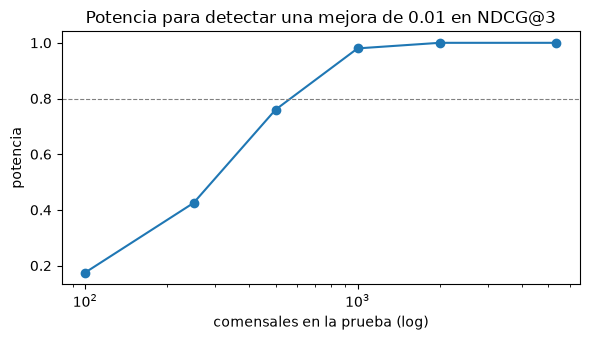

In [6]:
diff_ll = pq["lgbm"]["ndcg@3"] - pq["logística"]["ndcg@3"]
n_diners = pq["lgbm"]["diner_id"].nunique()
pot = power_curve(diff_ll, pq["lgbm"]["diner_id"], effect=MIN_GAIN, sizes=[100, 250, 500, 1000, 2000, n_diners],
                  n_sims=200, n_iter=500, seed=SEED)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(pot["comensales"], pot["potencia"], marker="o")
ax.axhline(0.8, color="grey", linestyle="--", linewidth=0.8)
ax.set_xscale("log"); ax.set_xlabel("comensales en la prueba (log)"); ax.set_ylabel("potencia")
ax.set_title(f"Potencia para detectar una mejora de {MIN_GAIN} en NDCG@3")
fig.tight_layout(); fig.savefig(paths.figures / "13_potencia.png", dpi=150)
pot.round(3)

## 5. Arranque en frío (contrafactual)

En la prueba temporal nadie es nuevo (notebook 10). Para saber cómo le va al modelo con alguien que **recién se registra**, se toman las mismas consultas de validación y se **borra la historia personal**: hábitos, picante y ticket habituales, platillos pedidos antes. Queda solo lo que Puzzle sabría de una persona nueva: el **onboarding** (picante y cocinas declaradas) y la **popularidad**.

Es un escenario "de laboratorio": la persona sigue pidiendo lo que habría pedido con su gusto real, pero el modelo ya no la conoce. Mide cuánto vale la historia.

In [7]:
repo = ParquetRepository(paths.synthetic / run_id_for(sim.run_name, sim.seed))
restaurants = repo.read_table("restaurants")
cuisines = sorted(restaurants["cuisine_pred"].unique())
share = restaurants["cuisine_pred"].value_counts(normalize=True).reindex(cuisines, fill_value=0)
prior = cuisine_prior(repo.read_table("diner_profiles"), share, declared_weight=load_yaml("features")["profile"]["declared_weight"])
frio = without_history(valid, prior)
pq_frio = por_consulta(frio, puntuar(frio))

filas = []
for k in pq:
    con = summarize(pq[k])["ndcg@3"].iloc[0]
    sin = summarize(pq_frio[k])["ndcg@3"].iloc[0]
    filas.append({"modelo": k, "con historia": con, "persona nueva": sin, "caída": con - sin})
display(pd.DataFrame(filas).round(4))
nuevo_onb = pd.concat([summarize(v, by="onboarding_completo").assign(modelo=k) for k, v in pq_frio.items()])
nuevo_onb.pivot(index="onboarding_completo", columns="modelo", values="ndcg@3").round(4)

,modelo,con historia,persona nueva,caída
0,popularidad,0.6565,0.6565,0.0000
1,logística,0.7027,0.6603,0.0424
2,lgbm,0.7371,0.6929,0.0442


modelo,lgbm,logística,popularidad
onboarding_completo,,,
False,0.6888,0.6615,0.6585
True,0.6955,0.6595,0.6552


### Restaurante nuevo (contrafactual)

Ahora se borra la popularidad **local**: el restaurante acaba de entrar a Puzzle y no tiene pedidos previos. Aquí se pone a prueba la **jerarquía de respaldo** del notebook 11. Con `N = 0`, la popularidad confía en el restaurante aunque no tenga historia: todos sus platillos empatan y el orden queda al azar. Con `N ≥ 1`, cae a la popularidad global del canónico.

In [8]:
nuevo_r = as_new_restaurant(valid)
q_info = valid.drop_duplicates("query_id").set_index("query_id")[["diner_id"]]
res_r = {
    "popularidad N = 0": popularity_score(nuevo_r, min_orders=0),
    "popularidad N = 1 (respaldo global)": popularity_score(nuevo_r, min_orders=1),
    "logística": logistica.predict_proba(model_frame(nuevo_r, FOR_YOU)[cols])[:, 1],
    "lgbm": predict(lgbm, nuevo_r, FOR_YOU, cats),
}
pd.DataFrame({k: summarize(rank_metrics(nuevo_r.assign(score=np.asarray(s)), ks=(3,), seed=SEED))[["ndcg@3", "hit@3"]].iloc[0]
              for k, s in res_r.items()}).T.round(4)

,ndcg@3,hit@3
popularidad N = 0,0.4659,0.6078
popularidad N = 1 (respaldo global),0.6393,0.7832
logística,0.6727,0.8130
lgbm,0.7090,0.8447


## Conclusiones

### 1. Sobreajuste: controlado

- **Curva de aprendizaje:** con el 5 % de los datos el modelo memoriza (0.90 en entrenamiento contra 0.72 en validación). Con todos los datos la brecha baja a **0.017** (0.754 contra 0.737). La validación **todavía sube** al final (0.735 → 0.737 al pasar del 50 % al 100 %), pero cada vez menos: más datos ayudarían poco.
- **Brecha final:** 0.021 para LightGBM y 0.006 para la logística. LightGBM memoriza un poco más, como todo modelo de árboles, pero su validación es mucho mejor, así que la complejidad se paga.

### 2. La mejora es real y relevante

| Comparación | Diferencia NDCG@3 | IC 95 % (por comensal) | p |
|---|---|---|---|
| Logística sobre popularidad | +0.046 | 0.044 a 0.049 | < 0.001 |
| LightGBM sobre popularidad | +0.081 | 0.077 a 0.084 | < 0.001 |
| **LightGBM sobre logística** | **+0.034** | **0.032 a 0.037** | **< 0.001** |

- Los tres intervalos quedan **lejos de 0** y **arriba de la mejora mínima relevante (0.01)**. Las dos pruebas (permutación con 5,000 cambios de signo y bootstrap pareado con 2,000 remuestreos, ambas por comensal) coinciden. El p-valor de la permutación es el mínimo posible con 5,000 iteraciones.
- **Dónde gana LightGBM:** sobre todo en **bebida** (+0.043) y **plato fuerte** (+0.038), los tipos con más opciones. En guarniciones la ganancia es mínima (+0.007, con intervalo de 0.001 a 0.012): con 1 o 2 opciones casi no hay nada que ordenar.

### 3. Potencia: los datos alcanzan de sobra

Para detectar una mejora de exactamente 0.01 con la prueba de permutación, la potencia es del **76 % con 500 comensales**, del **98 % con 1,000** y del 100 % desde 2,000. La validación tiene **5,370** y la prueba tiene un tamaño parecido. Si una diferencia relevante existiera, la prueba la vería; un resultado nulo en la prueba **no** se explicaría por falta de datos.

### 4. Persona nueva (contrafactual)

| Modelo | Con historia | Persona nueva | Caída |
|---|---|---|---|
| Popularidad | 0.657 | 0.657 | 0 |
| Logística | 0.703 | 0.660 | 0.042 |
| **LightGBM** | **0.737** | **0.693** | 0.044 |

- **La historia vale unos 0.044 de NDCG@3.** Sin ella, LightGBM pierde un poco más de la mitad de su ventaja sobre la popularidad, pero **sigue ganando** (+0.036), apoyado en el onboarding, el contexto y lo que se sabe del platillo.
- **El onboarding ayuda poco pero ayuda:** una persona nueva con onboarding completo obtiene 0.696 contra 0.689 sin él. La logística casi no lo aprovecha.
- **Para el lanzamiento:** desde la primera visita, LightGBM es mejor que mostrar "lo más pedido".

### 5. Restaurante nuevo (contrafactual): se corrige el respaldo

| Modelo | NDCG@3 |
|---|---|
| Popularidad con N = 0 | 0.466 (como el azar) |
| Popularidad con N = 1 (respaldo global) | 0.639 |
| Logística | 0.673 |
| **LightGBM** | **0.709** |

- **Hallazgo:** el `N = 0` elegido en el notebook 11 **falla con restaurantes nuevos**. Confía en una popularidad local que no existe, todos los platillos empatan y el orden queda al azar. En el mes 10 no se veía porque casi no había restaurantes sin historia. **Corrección:** `N = 1` (`config/features.yaml`, `fallback.restaurant_min_orders`). Con un solo pedido previo del restaurante ya se usa la popularidad local, y sin ninguno se cae a la global del canónico. En restaurantes con historia, `N = 1` y `N = 0` dan lo mismo (notebook 11).
- LightGBM pierde poco sin popularidad local (de 0.737 a 0.709), porque el canónico y la popularidad global la sustituyen.

**Pasa al notebook 14:** por qué decide así el modelo (SHAP) y si coincide con cómo se simuló la elección.
